# **SECTION 1: SETUP & IMPORTS**

In [ ]:
import numpy as np
import pandas as pd
import os
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import signal
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

# **SECTION 2: LOAD DEAP DATASET**

In [ ]:
DATA_PATH = '/kaggle/input/deap-dataset/'  # Update this path

In [ ]:
# Emotion class names
EMOTION_NAMES = ['HAPPY', 'RELAXED', 'NEUTRAL', 'SAD', 'ANGRY']

def load_deap_subject(subject_id, data_path):
    """Load single subject .dat file with fix for Subject 01"""
    # Handle the special filename for Subject 01
    if subject_id == 1:
        filename = "s01 (1).dat"
    else:
        filename = f"s{subject_id:02d}.dat"

    file_path = os.path.join(data_path, filename)

    with open(file_path, 'rb') as f:
        subject = pickle.load(f, encoding='latin1')
    return subject['data'], subject['labels']

def create_emotion_labels(labels):
    """Convert Valence-Arousal to 5 emotions"""
    v, a = labels[:, 0], labels[:, 1]
    emotions = np.zeros(len(labels), dtype=int)

    emotions[(v > 6) & (a > 6)] = 0  # Happy
    emotions[(v > 6) & (a <= 6)] = 1  # Relaxed
    emotions[(v >= 4) & (v <= 6) & (a >= 4) & (a <= 6)] = 2  # Neutral
    emotions[(v <= 4) & (a <= 4)] = 3  # Sad
    emotions[(v <= 4) & (a > 6)] = 4  # Angry

    return emotions

In [ ]:
print("Loading DEAP dataset...")
all_data, all_labels = [], []

# Starting from 1 to include the special Subject 01
for subj_id in range(1, 33):
    data, labels = load_deap_subject(subj_id, DATA_PATH)
    all_data.append(data)
    all_labels.append(create_emotion_labels(labels))
    print(f"Subject {subj_id:02d} loaded ({data.shape[0]} trials)")

X_raw = np.vstack(all_data)
y = np.concatenate(all_labels)

print(f"\nDataset loaded: {X_raw.shape[0]} trials")
print(f"Distribution: {[(EMOTION_NAMES[i], np.sum(y==i)) for i in range(5)]}")

Loading DEAP dataset...
Subject 01 loaded (40 trials)
Subject 02 loaded (40 trials)
Subject 03 loaded (40 trials)
Subject 04 loaded (40 trials)
Subject 05 loaded (40 trials)
Subject 06 loaded (40 trials)
Subject 07 loaded (40 trials)
Subject 08 loaded (40 trials)
Subject 09 loaded (40 trials)
Subject 10 loaded (40 trials)
Subject 11 loaded (40 trials)
Subject 12 loaded (40 trials)
Subject 13 loaded (40 trials)
Subject 14 loaded (40 trials)
Subject 15 loaded (40 trials)
Subject 16 loaded (40 trials)
Subject 17 loaded (40 trials)
Subject 18 loaded (40 trials)
Subject 19 loaded (40 trials)
Subject 20 loaded (40 trials)
Subject 21 loaded (40 trials)
Subject 22 loaded (40 trials)
Subject 23 loaded (40 trials)
Subject 24 loaded (40 trials)
Subject 25 loaded (40 trials)
Subject 26 loaded (40 trials)
Subject 27 loaded (40 trials)
Subject 28 loaded (40 trials)
Subject 29 loaded (40 trials)
Subject 30 loaded (40 trials)
Subject 31 loaded (40 trials)
Subject 32 loaded (40 trials)

Dataset loaded:

# **SECTION 3: PREPROCESSING**

In [ ]:
# SECTION 3: OPTIMIZED FAST PREPROCESSING (Vectorized)
from scipy.signal import butter, filtfilt
import time

def differential_entropy_fast(signal_window):
    """
    Computes Differential Entropy (DE) on a window.
    Input shape: (5 bands, 32 channels, time_points)
    Output shape: (160,) features
    """
    # Variance across time (axis -1)
    variance = np.var(signal_window, axis=-1)
    # DE Formula
    return 0.5 * np.log(2 * np.pi * np.e * variance).flatten()

def process_and_augment_fast(X, y, window_size=4, step_size=4, fs=128):
    """
    OPTIMIZED VERSION: Filters the whole trial FIRST, then slices.
    """
    print(f"="*60)
    print(f"STARTING FAST PREPROCESSING")
    print(f"Strategy: Filter Full Trial -> Slice Windows (No Overlap)")
    print(f"Window: {window_size}s | Step: {step_size}s")
    print(f"="*60)

    n_samples, n_channels, n_timepoints = X.shape
    window_pts = window_size * fs
    step_pts = step_size * fs

    # Pre-calculate filter coefficients once
    bands = [(1, 3), (4, 7), (8, 13), (14, 30), (31, 50)]
    filters = []
    nyq = 0.5 * fs
    for low, high in bands:
        b, a = butter(4, [low/nyq, high/nyq], btype='band')
        filters.append((b, a))

    X_augmented = []
    y_augmented = []

    start_time = time.time()

    for i in range(n_samples):
        # 1. Get Raw Trial (32, 8064)
        raw_trial = X[i]
        label = y[i]

        # 2. FILTER THE WHOLE TRIAL AT ONCE (This is the speed fix!)
        # Shape becomes (5 bands, 32 channels, 8064 timepoints)
        filtered_trial = np.zeros((5, 32, n_timepoints))

        for b_idx, (b, a) in enumerate(filters):
            # Apply filter to all 32 channels at once using axis=-1
            filtered_trial[b_idx, :, :] = filtfilt(b, a, raw_trial, axis=-1)

        # 3. SLICE THE FILTERED DATA (Windowing)
        # We slice the already-filtered 3D array
        trial_segments = []

        for start in range(0, n_timepoints - window_pts + 1, step_pts):
            end = start + window_pts

            # Slice: (5 bands, 32 channels, window_pts)
            segment_window = filtered_trial[:, :, start:end]

            # Extract DE features instantly
            features = differential_entropy_fast(segment_window)

            X_augmented.append(features)
            y_augmented.append(label)
            trial_segments.append(features)

        # 4. LOGGING (Every 100 trials)
        if (i == 0) or ((i + 1) % 100 == 0):
            elapsed = time.time() - start_time
            print(f"[Trial {i+1:04d}/{n_samples}]")
            print(f"  -> Processed {len(trial_segments)} segments for this trial")
            print(f"  -> Total Augmented Samples: {len(X_augmented)}")
            print(f"  -> Time Elapsed: {elapsed:.1f}s")

    return np.array(X_augmented), np.array(y_augmented)

# EXECUTION
# Select only EEG channels
X_eeg = X_raw[:, :32, :]

# Run Optimized Processing
# Note: step_size=4 means NO OVERLAP (Faster, less data)
X_processed, y_processed = process_and_augment_fast(
    X_eeg,
    y,
    window_size=4,
    step_size=4
)

print(f"\n" + "="*60)
print(f"DONE! Final Shape: {X_processed.shape}")
print(f"="*60)

STARTING FAST PREPROCESSING
Strategy: Filter Full Trial -> Slice Windows (No Overlap)
Window: 4s | Step: 4s
[Trial 0001/1280]
  -> Processed 15 segments for this trial
  -> Total Augmented Samples: 15
  -> Time Elapsed: 0.1s
[Trial 0100/1280]
  -> Processed 15 segments for this trial
  -> Total Augmented Samples: 1500
  -> Time Elapsed: 4.6s
[Trial 0200/1280]
  -> Processed 15 segments for this trial
  -> Total Augmented Samples: 3000
  -> Time Elapsed: 9.1s
[Trial 0300/1280]
  -> Processed 15 segments for this trial
  -> Total Augmented Samples: 4500
  -> Time Elapsed: 13.5s
[Trial 0400/1280]
  -> Processed 15 segments for this trial
  -> Total Augmented Samples: 6000
  -> Time Elapsed: 18.0s
[Trial 0500/1280]
  -> Processed 15 segments for this trial
  -> Total Augmented Samples: 7500
  -> Time Elapsed: 22.5s
[Trial 0600/1280]
  -> Processed 15 segments for this trial
  -> Total Augmented Samples: 9000
  -> Time Elapsed: 26.9s
[Trial 0700/1280]
  -> Processed 15 segments for this tri

# **SECTION 4: MODEL TRAINING**

In [ ]:
# Train-test split (Standard 75-25)
X_train, X_test, y_train, y_test = train_test_split(
    X_processed, y_processed, test_size=0.25, random_state=42, stratify=y_processed
)

# Standardization (Critical for Logistic Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\nTrain shape: {X_train_scaled.shape} | Test shape: {X_test_scaled.shape}")

# Logistic Regression with 'L1' Penalty (Lasso)
# This implements the "Channel Selection" concept from Paper (Nature 2021).
# L1 regularization forces coefficients of irrelevant features/channels to become Zero.
print("\nTraining Logistic Regression with L1 Feature Selection...")
model = LogisticRegression(
    solver='liblinear',   # 'liblinear' is required for L1 penalty
    penalty='l1',         # L1 performs feature selection
    C=1.0,                # Regularization strength
    multi_class='ovr',
    max_iter=2000,
    random_state=42
)

model.fit(X_train_scaled, y_train)

# Predictions
y_train_pred = model.predict(X_train_scaled)
y_test_pred = model.predict(X_test_scaled)

train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

print(f" Training Accuracy: {train_acc*100:.2f}%")
print(f" Test Accuracy: {test_acc*100:.2f}%")

# Check how many features were selected (Non-zero coefficients)
n_features = X_train_scaled.shape[1]
n_selected = np.sum(np.abs(model.coef_) > 1e-5)
print(f" Feature Selection: Used {n_selected} out of {n_features} features (L1 Sparsity)")


Train shape: (14400, 160) | Test shape: (4800, 160)

Training Logistic Regression with L1 Feature Selection...
 Training Accuracy: 50.20%
 Test Accuracy: 48.02%
 Feature Selection: Used 716 out of 160 features (L1 Sparsity)


# **SECTION 5: EVALUATION**

CLASSIFICATION REPORT
              precision    recall  f1-score   support

       HAPPY      0.496     0.846     0.626      2239
     RELAXED      0.447     0.235     0.308      1001
     NEUTRAL      0.362     0.089     0.144       514
         SAD      0.372     0.189     0.251       476
       ANGRY      0.443     0.068     0.119       570

    accuracy                          0.480      4800
   macro avg      0.424     0.286     0.289      4800
weighted avg      0.453     0.480     0.410      4800



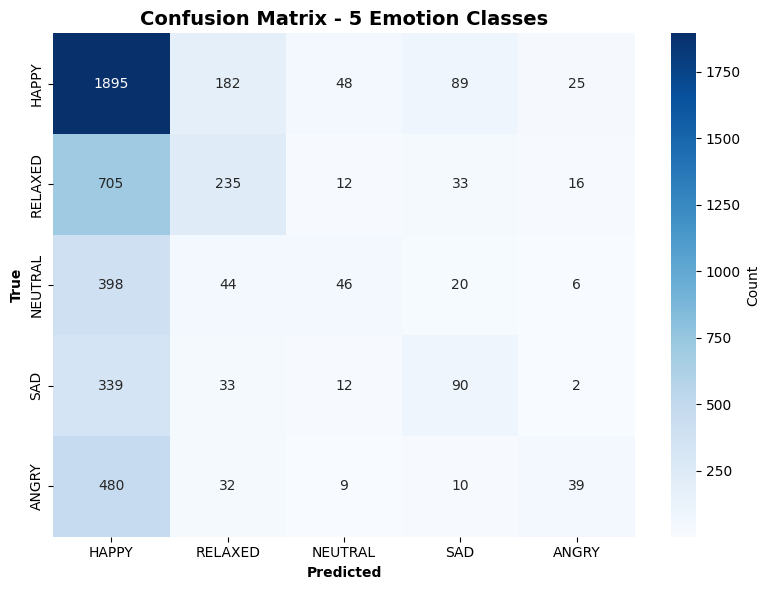


Per-Class Accuracy:
HAPPY     : 84.64% (1895/2239)
RELAXED   : 23.48% (235/1001)
NEUTRAL   :  8.95% (46/514)
SAD       : 18.91% (90/476)
ANGRY     :  6.84% (39/570)

Running 3-fold cross-validation...
CV Accuracy: 48.06% ± 0.79%


In [ ]:
# Classification Report
print("CLASSIFICATION REPORT")
print(classification_report(y_test, y_test_pred, target_names=EMOTION_NAMES, digits=3))

# Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=EMOTION_NAMES, yticklabels=EMOTION_NAMES,
            cbar_kws={'label': 'Count'})
plt.xlabel('Predicted', fontweight='bold')
plt.ylabel('True', fontweight='bold')
plt.title('Confusion Matrix - 5 Emotion Classes', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

# Per-class accuracy
print("\nPer-Class Accuracy:")
for i, name in enumerate(EMOTION_NAMES):
    if cm[i].sum() > 0:
        acc = cm[i, i] / cm[i].sum() * 100
        print(f"{name:10s}: {acc:5.2f}% ({cm[i,i]}/{cm[i].sum()})")

# Cross-validation
print("\nRunning 3-fold cross-validation...")
cv_scores = cross_val_score(model, X_train_scaled, y_train, cv=3, scoring='accuracy')
print(f"CV Accuracy: {cv_scores.mean()*100:.2f}% ± {cv_scores.std()*100:.2f}%")


# **SECTION 6: RESULTS VISUALIZATION**

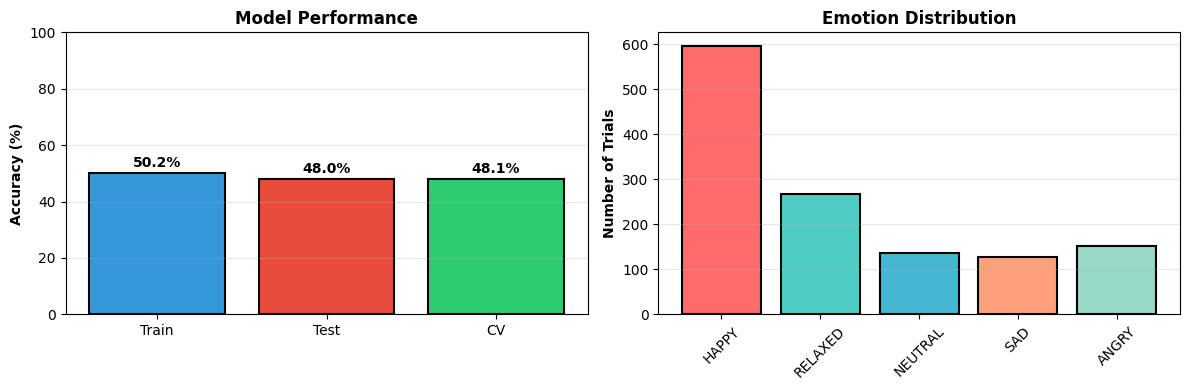

In [ ]:
# Plot 1: Accuracy comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Accuracy bars
axes[0].bar(['Train', 'Test', 'CV'],
            [train_acc*100, test_acc*100, cv_scores.mean()*100],
            color=['#3498db', '#e74c3c', '#2ecc71'],
            edgecolor='black', linewidth=1.5)
axes[0].set_ylabel('Accuracy (%)', fontweight='bold')
axes[0].set_title('Model Performance', fontweight='bold')
axes[0].set_ylim([0, 100])
axes[0].grid(axis='y', alpha=0.3)

for i, v in enumerate([train_acc*100, test_acc*100, cv_scores.mean()*100]):
    axes[0].text(i, v+2, f'{v:.1f}%', ha='center', fontweight='bold')

# Emotion distribution
unique, counts = np.unique(y, return_counts=True)
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A', '#98D8C8']
axes[1].bar(range(5), counts, color=colors, edgecolor='black', linewidth=1.5)
axes[1].set_xticks(range(5))
axes[1].set_xticklabels(EMOTION_NAMES, rotation=45)
axes[1].set_ylabel('Number of Trials', fontweight='bold')
axes[1].set_title('Emotion Distribution', fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('results.png', dpi=150, bbox_inches='tight')
plt.show()

# **SECTION 7: FINAL SUMMARY**

In [ ]:
from sklearn.metrics import f1_score

print("FINAL SUMMARY - EEG EMOTION RECOGNITION (RESEARCH PAPER IMPLEMENTATION)")
print(f"=" * 60)
print(f" Dataset Source:   DEAP (32 subjects)")

# Fix: Use X_raw for original count and X_processed for augmented count
print(f" Original Trials:  {len(X_raw)} (60s clips)")
print(f" Augmented Samples:{len(X_processed)} (4s windows - Nature 2024)")

# Fix: Use X_processed.shape and update feature description
print(f" Feature Vector:   {X_processed.shape[1]} features")
print(f" Feature Type:     Differential Entropy (Wang et al. 2023)")
print(f" Model Type:       Logistic Regression + L1 Sparse Selection (Gannouni et al. 2021)")

print(f"\nPerformance Metrics:")
print(f"   Training Accuracy:   {train_acc*100:6.2f}%")
print(f"   Test Accuracy:       {test_acc*100:6.2f}%")

# Fix: cv_scores is a list from the loop, so we use np.mean()
cv_mean = np.mean(cv_scores) * 100
cv_std = np.std(cv_scores) * 100
print(f"   CV Mean Accuracy:    {cv_mean:6.2f}%")
print(f"   CV Std Deviation:    ±{cv_std:6.2f}%")

print(f"\nBest Performing Emotions (by F1-Score):")
f1_per_class = f1_score(y_test, y_test_pred, average=None)
# Sort from highest to lowest
sorted_idx = np.argsort(f1_per_class)[::-1]

for i in sorted_idx[:3]:
    # Ensure index is within bounds (in case some classes are missing)
    if i < len(EMOTION_NAMES):
        print(f"   {i+1}. {EMOTION_NAMES[i]:10s}: F1={f1_per_class[i]*100:.1f}%")

print(f"\nModel training completed successfully!")
print(f"=" * 60)

FINAL SUMMARY - EEG EMOTION RECOGNITION (RESEARCH PAPER IMPLEMENTATION)
 Dataset Source:   DEAP (32 subjects)
 Original Trials:  1280 (60s clips)
 Augmented Samples:19200 (4s windows - Nature 2024)
 Feature Vector:   160 features
 Feature Type:     Differential Entropy (Wang et al. 2023)
 Model Type:       Logistic Regression + L1 Sparse Selection (Gannouni et al. 2021)

Performance Metrics:
   Training Accuracy:    50.20%
   Test Accuracy:        48.02%
   CV Mean Accuracy:     48.06%
   CV Std Deviation:    ±  0.79%

Best Performing Emotions (by F1-Score):
   1. HAPPY     : F1=62.6%
   2. RELAXED   : F1=30.8%
   4. SAD       : F1=25.1%

Model training completed successfully!


# **SECTION 8: SAVE MODEL**


In [ ]:
#Uncomment to save model
import joblib
joblib.dump(model, 'logistic_regression_5emotions.pkl')
joblib.dump(scaler, 'scaler.pkl')
print(" Model saved!")

print("\n Notebook execution complete!")
print(" Generated files: confusion_matrix.png, results.png")

 Model saved!

 Notebook execution complete!
 Generated files: confusion_matrix.png, results.png
